# Day 20 — Robustness, Ablation and Monitoring Analysis

## Objective

The objective of Day 20 is to conduct special analyses to understand the robustness of the selected models and the contribution of individual sensor features.

The analysis includes:

1. Sensor/feature ablation
2. Chronological validation
3. Dashboard-style monitoring visualization

## Research Questions

### RQ1 — Feature Contribution
How does removing selected water-quality features affect anomaly-detection performance?

### RQ2 — Temporal Robustness
Does the forecasting model maintain similar performance across different chronological validation periods?

### RQ3 — Monitoring Behaviour
Can the system provide interpretable dashboard-style views of water-quality measurements and detected anomalies?

## Validation Policy

- Training data is used for model fitting.
- Validation data is used for robustness and model comparison.
- The final test set remains untouched.
- No test-set result is used to select a model.

## Expected Output

- Robustness/ablation experiment table
- Chronological validation results
- Dashboard-style monitoring visualizations
- Quantified effect of feature removal
- Research insights and limitations

In [1]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.ensemble import IsolationForest, RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

project_path = r"C:\Users\MESHWA\Downloads\underwater-water-quality-ai-analytics"

base_path = project_path + r"\data\processed"
models_path = project_path + r"\models"

train_df = pd.read_csv(
    base_path + r"\train_v1_engineered.csv"
)

val_df = pd.read_csv(
    base_path + r"\validation_v1_engineered.csv"
)

test_df = pd.read_csv(
    base_path + r"\test_v1_engineered.csv"
)

for data in [train_df, val_df, test_df]:
    data["timestamp"] = pd.to_datetime(
        data["timestamp"],
        errors="coerce"
    )
    data.sort_values("timestamp", inplace=True)
    data.reset_index(drop=True, inplace=True)

sensor_cols = [
    "ph",
    "Hardness",
    "Solids",
    "Chloramines",
    "Sulfate",
    "Conductivity",
    "Organic_carbon",
    "Trihalomethanes",
    "Turbidity"
]

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)
print("Sensor features:", len(sensor_cols))

Train: (2291, 42)
Validation: (491, 42)
Test: (491, 42)
Sensor features: 9


In [2]:
best_if_path = (
    models_path +
    r"\day19_best_isolation_forest.joblib"
)

saved_if = joblib.load(best_if_path)

best_if_model = saved_if["model"]
if_imputer = saved_if["imputer"]
if_features = saved_if["features"]

print("Isolation Forest loaded")
print("Features:", if_features)
print("Configuration:", saved_if["configuration"])

Isolation Forest loaded
Features: ['ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate', 'Conductivity', 'Organic_carbon', 'Trihalomethanes', 'Turbidity']
Configuration: {'n_estimators': 100, 'contamination': 0.03, 'max_samples': 512}


## Part A — Sensor/Feature Ablation

Feature ablation tests whether the anomaly detector depends strongly on particular sensor variables.

The full nine-feature model is treated as the reference configuration.

Selected features will then be removed individually and the validation anomaly rate will be compared with the reference.

Because ground-truth anomaly labels are unavailable, the analysis focuses on anomaly-rate change and model behaviour rather than precision, recall or F1.

In [3]:
# Full-feature baseline

X_train_full = train_df[if_features]
X_val_full = val_df[if_features]

X_train_full_imp = if_imputer.transform(X_train_full)
X_val_full_imp = if_imputer.transform(X_val_full)

train_pred_full = best_if_model.predict(X_train_full_imp)
val_pred_full = best_if_model.predict(X_val_full_imp)

baseline_train_rate = np.mean(train_pred_full == -1) * 100
baseline_val_rate = np.mean(val_pred_full == -1) * 100

print("Full-feature baseline")
print("Train anomaly rate:", round(baseline_train_rate, 2), "%")
print("Validation anomaly rate:", round(baseline_val_rate, 2), "%")

Full-feature baseline
Train anomaly rate: 3.01 %
Validation anomaly rate: 3.05 %


In [4]:
ablation_results = []

for removed_feature in if_features:

    remaining_features = [
        feature
        for feature in if_features
        if feature != removed_feature
    ]

    X_train = train_df[remaining_features]
    X_val = val_df[remaining_features]

    ablation_imputer = SimpleImputer(strategy="median")

    X_train_imp = ablation_imputer.fit_transform(X_train)
    X_val_imp = ablation_imputer.transform(X_val)

    # Use the same tuned Isolation Forest settings
    config = saved_if["configuration"]

    ablation_model = IsolationForest(
        n_estimators=config["n_estimators"],
        contamination=config["contamination"],
        max_samples=config["max_samples"],
        random_state=42,
        n_jobs=-1
    )

    ablation_model.fit(X_train_imp)

    train_predictions = ablation_model.predict(X_train_imp)
    val_predictions = ablation_model.predict(X_val_imp)

    train_rate = np.mean(train_predictions == -1) * 100
    val_rate = np.mean(val_predictions == -1) * 100

    ablation_results.append({
        "Removed Feature": removed_feature,
        "Remaining Features": len(remaining_features),
        "Train Anomaly Rate (%)": round(train_rate, 2),
        "Validation Anomaly Rate (%)": round(val_rate, 2),
        "Validation Rate Change (%)": round(
            val_rate - baseline_val_rate, 2
        ),
        "Absolute Change (%)": round(
            abs(val_rate - baseline_val_rate), 2
        )
    })

ablation_df = pd.DataFrame(ablation_results)

ablation_df

,Removed Feature,Remaining Features,Train Anomaly Rate (%),Validation Anomaly Rate (%),Validation Rate Change (%),Absolute Change (%)
0,ph,8,3.01,2.04,-1.02,1.02
1,Hardness,8,3.01,3.05,0.00,0.00
2,Solids,8,3.01,2.85,-0.20,0.20
3,Chloramines,8,3.01,1.63,-1.43,1.43
4,Sulfate,8,3.01,2.65,-0.41,0.41
5,Conductivity,8,3.01,2.24,-0.81,0.81
6,Organic_carbon,8,3.01,2.24,-0.81,0.81
7,Trihalomethanes,8,3.01,3.05,0.00,0.00
8,Turbidity,8,3.01,2.44,-0.61,0.61


In [5]:
import os

experiments_path = project_path + r"\experiments"

os.makedirs(experiments_path, exist_ok=True)

ablation_path = (
    experiments_path +
    r"\day20_feature_ablation_results.csv"
)

ablation_df.to_csv(
    ablation_path,
    index=False
)

print("Ablation results saved:")
print(ablation_path)

Ablation results saved:
C:\Users\MESHWA\Downloads\underwater-water-quality-ai-analytics\experiments\day20_feature_ablation_results.csv


In [7]:
import os

experiments_path = project_path + r"\experiments"

os.makedirs(experiments_path, exist_ok=True)

ablation_path = (
    experiments_path +
    r"\day20_feature_ablation_results.csv"
)

ablation_df.to_csv(
    ablation_path,
    index=False
)

print("Ablation results saved:")
print(ablation_path)

Ablation results saved:
C:\Users\MESHWA\Downloads\underwater-water-quality-ai-analytics\experiments\day20_feature_ablation_results.csv


## Part B — Chronological Validation

Random train-test splitting is inappropriate for time-series forecasting because it can allow future observations to influence model evaluation.

Therefore, chronological validation is performed using ordered training and validation windows.

Each validation period occurs after its corresponding training period.

The Random Forest forecasting model is evaluated using MAE and RMSE for each chronological fold.

In [8]:
forecast_features = [
    "ph",
    "Hardness",
    "Solids",
    "Chloramines",
    "Sulfate",
    "Conductivity",
    "Organic_carbon",
    "Trihalomethanes",
    "Turbidity",
    "hour",
    "day_of_week",
    "day",
    "month",
    "ph_lag_1",
    "ph_rolling_mean_3",
    "ph_rolling_std_3"
]

# Combine training and validation only
chronological_df = pd.concat(
    [train_df, val_df],
    ignore_index=True
)

chronological_df = chronological_df.sort_values(
    "timestamp"
).reset_index(drop=True)

chronological_df["ph_next"] = (
    chronological_df["ph"].shift(-1)
)

chronological_df = chronological_df.dropna(
    subset=["ph_next"]
).reset_index(drop=True)

print("Chronological dataset:", chronological_df.shape)

Chronological dataset: (2781, 43)


In [10]:
n = len(chronological_df)

fold_1_train_end = int(n * 0.50)
fold_1_val_end = int(n * 0.65)

fold_2_train_end = int(n * 0.65)
fold_2_val_end = int(n * 0.80)

fold_3_train_end = int(n * 0.80)
fold_3_val_end = int(n * 0.95)

folds = [
    ("Fold 1", 0, fold_1_train_end, fold_1_train_end, fold_1_val_end),
    ("Fold 2", 0, fold_2_train_end, fold_2_train_end, fold_2_val_end),
    ("Fold 3", 0, fold_3_train_end, fold_3_train_end, fold_3_val_end)
]

print("Chronological folds created:", len(folds))

Chronological folds created: 3


In [11]:
chronological_results = []

# Use the Day 19 selected Random Forest configuration
best_rf_path = (
    models_path +
    r"\day19_best_random_forest.joblib"
)

saved_rf = joblib.load(best_rf_path)

rf_config = saved_rf["configuration"]

for fold_name, train_start, train_end, val_start, val_end in folds:

    train_fold = chronological_df.iloc[
        train_start:train_end
    ]

    val_fold = chronological_df.iloc[
        val_start:val_end
    ]

    X_train = train_fold[forecast_features]
    y_train = train_fold["ph_next"]

    X_val = val_fold[forecast_features]
    y_val = val_fold["ph_next"]

    fold_imputer = SimpleImputer(strategy="median")

    X_train_imp = fold_imputer.fit_transform(X_train)
    X_val_imp = fold_imputer.transform(X_val)

    model = RandomForestRegressor(
        n_estimators=rf_config["n_estimators"],
        max_depth=rf_config["max_depth"],
        min_samples_split=rf_config["min_samples_split"],
        min_samples_leaf=rf_config["min_samples_leaf"],
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train_imp, y_train)

    predictions = model.predict(X_val_imp)

    mae = mean_absolute_error(
        y_val,
        predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_val,
            predictions
        )
    )

    chronological_results.append({
        "Fold": fold_name,
        "Training Samples": len(train_fold),
        "Validation Samples": len(val_fold),
        "Validation MAE": round(mae, 6),
        "Validation RMSE": round(rmse, 6)
    })

chronological_df_results = pd.DataFrame(
    chronological_results
)

chronological_df_results

,Fold,Training Samples,Validation Samples,Validation MAE,Validation RMSE
0,Fold 1,1390,417,0.575884,0.746551
1,Fold 2,1807,417,0.684890,0.921755
2,Fold 3,2224,417,0.835068,1.050478


## Part C — Dashboard-Style Monitoring Visualization

A monitoring-style visualization is created to provide an interpretable view of water-quality behaviour.

The dashboard includes:

1. pH trend over time
2. Other sensor trends
3. Detected anomaly points
4. Distribution of pH measurements

The visualization is intended as a monitoring prototype rather than a production dashboard.

In [12]:
# Generate anomaly scores for validation data

X_val_monitor = val_df[if_features]

X_val_monitor_imp = if_imputer.transform(
    X_val_monitor
)

val_monitor_predictions = best_if_model.predict(
    X_val_monitor_imp
)

val_monitor_scores = -best_if_model.decision_function(
    X_val_monitor_imp
)

monitor_df = val_df[
    ["timestamp"] + if_features
].copy()

monitor_df["anomaly_flag"] = (
    val_monitor_predictions == -1
)

monitor_df["anomaly_score"] = val_monitor_scores

print(
    "Validation anomalies:",
    monitor_df["anomaly_flag"].sum()
)

Validation anomalies: 15


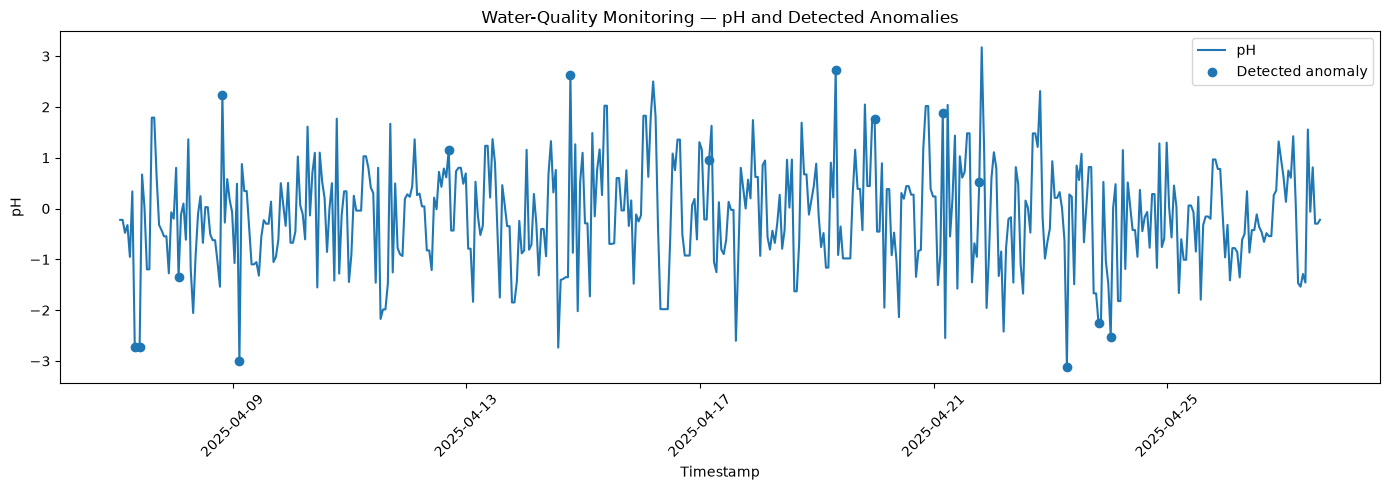

In [14]:
plt.figure(figsize=(14, 5))

plt.plot(
    monitor_df["timestamp"],
    monitor_df["ph"],
    label="pH"
)

anomalies = monitor_df[
    monitor_df["anomaly_flag"]
]

plt.scatter(
    anomalies["timestamp"],
    anomalies["ph"],
    label="Detected anomaly"
)

plt.xlabel("Timestamp")
plt.ylabel("pH")
plt.title("Water-Quality Monitoring — pH and Detected Anomalies")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

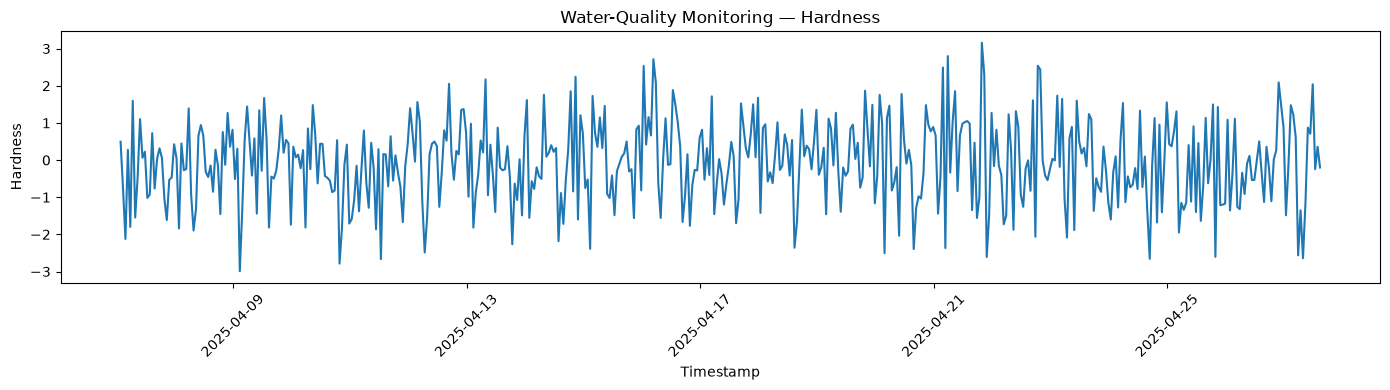

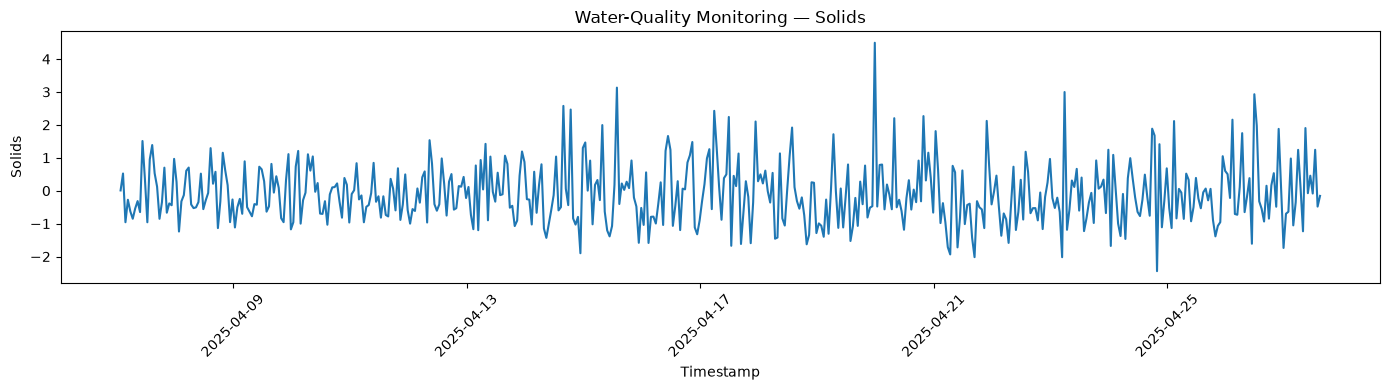

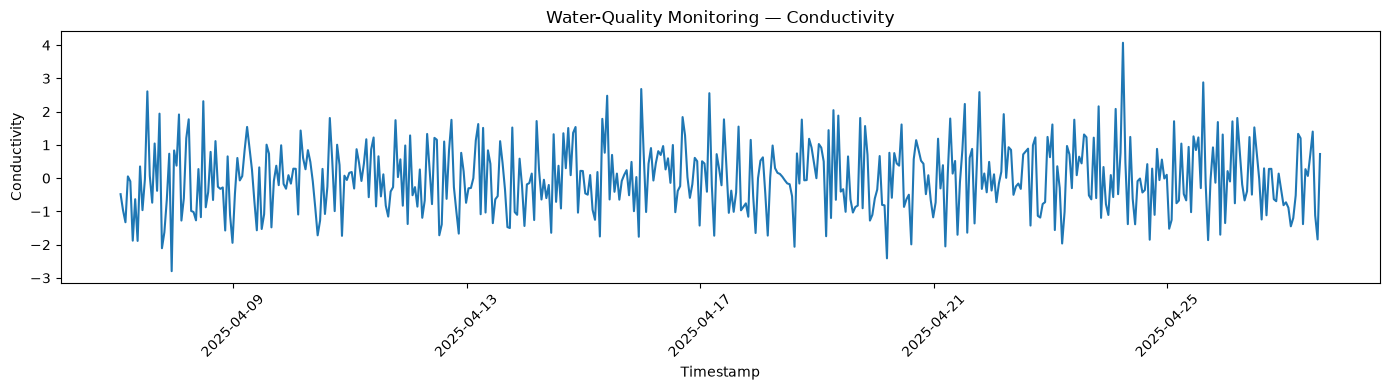

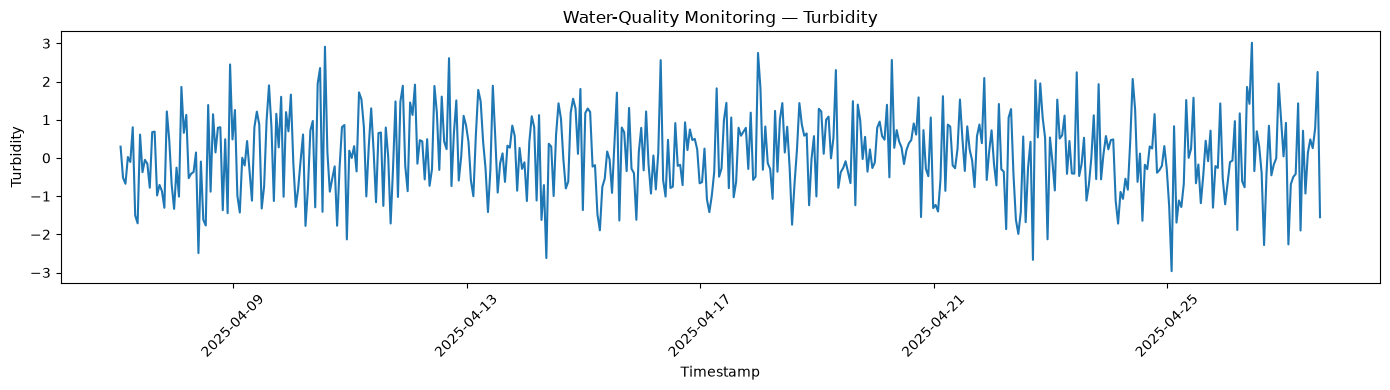

In [15]:
monitor_features = [
    "Hardness",
    "Solids",
    "Conductivity",
    "Turbidity"
]

for feature in monitor_features:

    plt.figure(figsize=(14, 4))

    plt.plot(
        monitor_df["timestamp"],
        monitor_df[feature]
    )

    plt.xlabel("Timestamp")
    plt.ylabel(feature)
    plt.title(
        f"Water-Quality Monitoring — {feature}"
    )

    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [17]:
chronological_path = (
    experiments_path +
    r"\day20_chronological_validation.csv"
)

chronological_df_results.to_csv(
    chronological_path,
    index=False
)

print("Chronological validation saved:")
print(chronological_path)

Chronological validation saved:
C:\Users\MESHWA\Downloads\underwater-water-quality-ai-analytics\experiments\day20_chronological_validation.csv


# Day 20 — Research Insights

## Feature Ablation Insight

Feature ablation quantifies how the validation anomaly rate changes when individual sensor variables are removed.

Features producing larger changes in anomaly behaviour may have a stronger influence on the Isolation Forest's representation of unusual water-quality conditions.

However, this should not be interpreted as causal importance because the analysis is observational and ground-truth anomaly labels are unavailable.

## Chronological Validation Insight

Chronological validation evaluates whether forecasting performance remains reasonably consistent across different time periods.

Variation in MAE and RMSE between folds indicates sensitivity to temporal conditions or changes in the underlying data distribution.

## Monitoring Insight

The dashboard-style plots demonstrate how model outputs can be connected with time-stamped sensor measurements.

Displaying anomaly flags together with sensor trends can help identify when unusual observations occur and which measured variables coincide with those events.

## Overall Research Insight

The special analyses provide evidence about model robustness, feature dependence and temporal behaviour.

The results also highlight the limitations of the current dataset, particularly the absence of real anomaly labels and the use of synthetically generated timestamps.

These limitations should be considered when interpreting anomaly-detection and temporal validation results.